# Automated Product Image Tagging with Deep Learning
### Fashion-MNIST image classification: MLP vs. CNN vs. regularized CNN

**Main objective.** Build a model that **predicts** the product category of a clothing image, so that an online retailer can automatically tag new catalog photos instead of tagging them by hand. The focus is **prediction accuracy**, not interpretation, although we also look at *which* categories the model confuses because that drives the business process around it.

**Stakeholder value.** Manual tagging is slow and inconsistent. An accurate classifier can auto-tag most incoming images, sending only low-confidence images to a human reviewer. This cuts labor cost and speeds up time-to-listing.

**Notebook outline**
1. Data description and exploration
2. Preprocessing
3. Three deep learning model variations (MLP baseline, basic CNN, regularized CNN)
4. Model comparison and selection
5. Final test-set evaluation and error analysis
6. Business view: confidence thresholds for human-in-the-loop tagging

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")  # Keras 3 is backend-agnostic; PyTorch gives GPU access on this machine

import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 42
keras.utils.set_random_seed(SEED)
# PyTorch's native image layout is channels-first; using it avoids a transpose around every
# convolution and made training about 12x faster on this machine's GPU.
keras.config.set_image_data_format("channels_first")

FIG_DIR = Path("figures")
OUT_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
MODEL_COLORS = {"MLP baseline": "#8c8c8c", "Basic CNN": "#4c72b0", "Regularized CNN": "#dd8452"}
sns.set_theme(style="whitegrid")

print(f"Keras {keras.__version__} | backend: {keras.backend.backend()}")
if keras.backend.backend() == "torch":
    import torch
    print("Accelerator:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

Keras 3.15.1 | backend: torch
Accelerator: AMD Radeon RX 7900 XT


## 1. Data description and exploration

**Fashion-MNIST** (Zalando Research) contains 70,000 grayscale product photos of clothing, each 28 x 28 pixels and labeled with one of 10 categories. It ships with Keras, already split into 60,000 training and 10,000 test images.

* **Features:** 784 pixel intensities per image (integers 0-255, where 0 is the background).
* **Target:** product category (10 classes, integer-encoded 0-9).

In [2]:
(x_train_full, y_train_full), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

print("Training images:", x_train_full.shape, "| labels:", y_train_full.shape)
print("Test images:    ", x_test.shape, "| labels:", y_test.shape)
print("Pixel dtype and range:", x_train_full.dtype, x_train_full.min(), "-", x_train_full.max())
print("Exact duplicate images in training set:", len(x_train_full) - len(np.unique(x_train_full.reshape(len(x_train_full), -1), axis=0)))

class_counts = pd.DataFrame({
    "category": CLASS_NAMES,
    "train": np.bincount(y_train_full, minlength=10),
    "test": np.bincount(y_test, minlength=10),
})
class_counts

Training images: (60000, 28, 28) | labels: (60000,)
Test images:     (10000, 28, 28) | labels: (10000,)
Pixel dtype and range: uint8 0 - 255


Exact duplicate images in training set: 0


,category,train,test
0,T-shirt/top,6000,1000
1,Trouser,6000,1000
2,Pullover,6000,1000
3,Dress,6000,1000
4,Coat,6000,1000
5,Sandal,6000,1000
6,Shirt,6000,1000
7,Sneaker,6000,1000
8,Bag,6000,1000
9,Ankle boot,6000,1000


The classes are **perfectly balanced** (6,000 training and 1,000 test images each), so plain accuracy is a fair headline metric and no resampling or class weighting is needed. There are no missing values: every image is a complete 28 x 28 array.

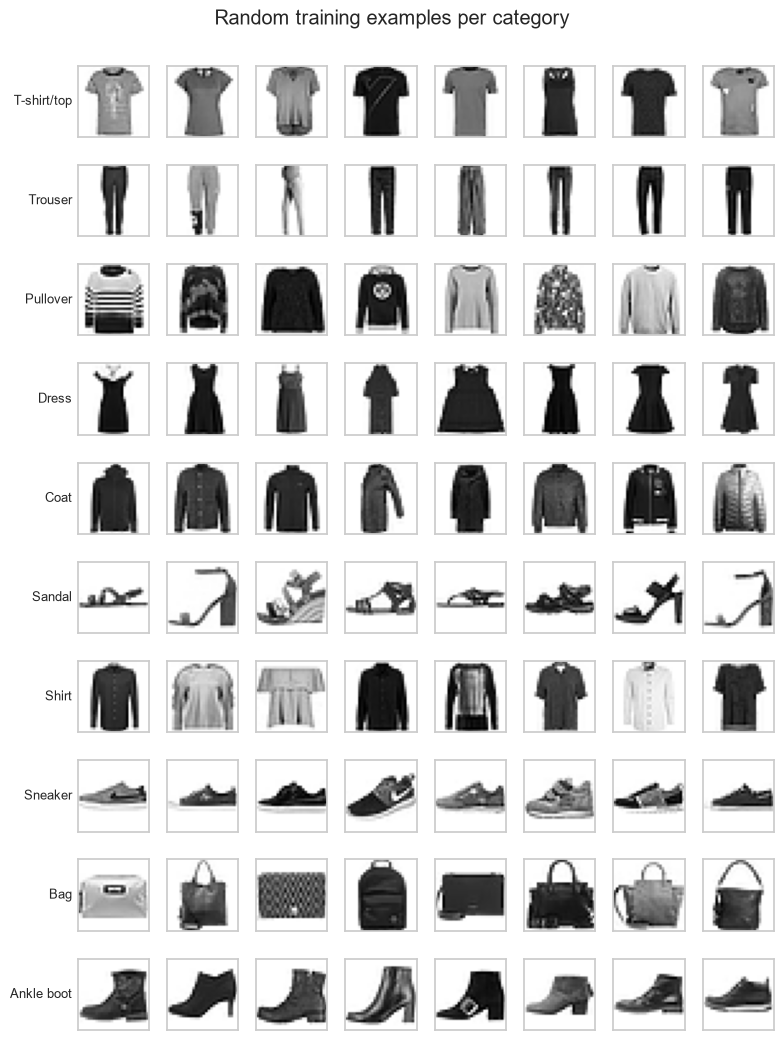

In [3]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(10, 8, figsize=(8, 10.5))
for c in range(10):
    picks = rng.choice(np.flatnonzero(y_train_full == c), 8, replace=False)
    for j, i in enumerate(picks):
        ax = axes[c, j]
        ax.imshow(x_train_full[i], cmap="gray_r")
        ax.set_xticks([]); ax.set_yticks([])
    axes[c, 0].set_ylabel(CLASS_NAMES[c], rotation=0, ha="right", va="center", fontsize=9)
fig.suptitle("Random training examples per category", y=0.995)
fig.tight_layout()
fig.savefig(FIG_DIR / "sample_grid.png", dpi=150, bbox_inches="tight")
plt.show()

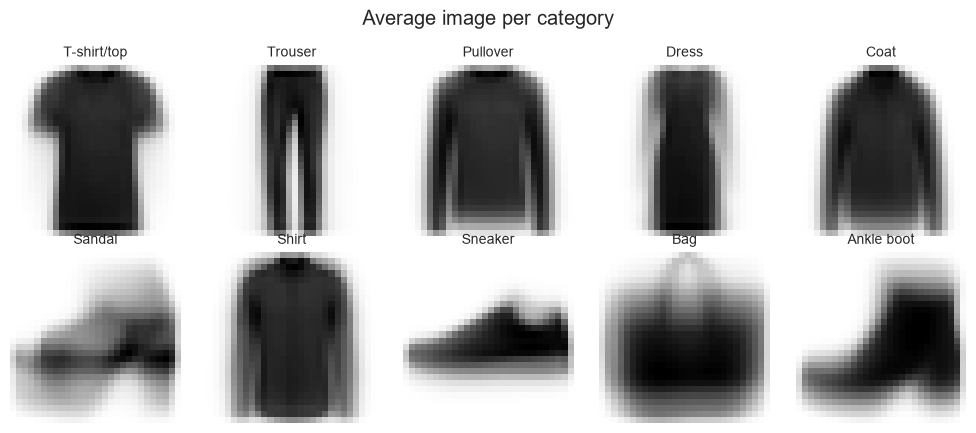

,category,mean_intensity,pct_pixels_nonzero
0,T-shirt/top,83.0,59.4
1,Trouser,56.8,34.9
2,Pullover,96.1,64.9
3,Dress,66.0,42.8
4,Coat,98.3,60.2
5,Sandal,34.9,32.1
6,Shirt,84.6,62.9
7,Sneaker,42.8,33.8
8,Bag,90.2,58.6
9,Ankle boot,76.8,48.5


In [4]:
mean_images = np.stack([x_train_full[y_train_full == c].mean(axis=0) for c in range(10)])

fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
for c, ax in enumerate(axes.flat):
    ax.imshow(mean_images[c], cmap="gray_r")
    ax.set_title(CLASS_NAMES[c], fontsize=10)
    ax.axis("off")
fig.suptitle("Average image per category")
fig.tight_layout()
fig.savefig(FIG_DIR / "class_means.png", dpi=150, bbox_inches="tight")
plt.show()

# Per-category pixel statistics: overall brightness and how much of the frame the item covers
pixel_stats = pd.DataFrame({
    "category": CLASS_NAMES,
    "mean_intensity": [x_train_full[y_train_full == c].mean() for c in range(10)],
    "pct_pixels_nonzero": [100 * (x_train_full[y_train_full == c] > 0).mean() for c in range(10)],
}).round(1)
pixel_stats

In [5]:
# Cosine similarity between average images hints at which categories will be hard to separate
flat = mean_images.reshape(10, -1)
flat = flat / np.linalg.norm(flat, axis=1, keepdims=True)
similarity = flat @ flat.T

pairs = [(CLASS_NAMES[i], CLASS_NAMES[j], similarity[i, j]) for i in range(10) for j in range(i + 1, 10)]
most_similar = pd.DataFrame(pairs, columns=["category A", "category B", "cosine similarity"])
most_similar = most_similar.sort_values("cosine similarity", ascending=False).head(6).reset_index(drop=True)
most_similar.round(3)

,category A,category B,cosine similarity
0,Coat,Shirt,0.987
1,Pullover,Coat,0.984
2,Pullover,Shirt,0.983
3,T-shirt/top,Shirt,0.949
4,Sandal,Ankle boot,0.927
5,Trouser,Dress,0.925


**Exploration takeaways**
* The upper-body garments (**T-shirt/top, Pullover, Coat, Shirt**) have nearly identical average silhouettes. These are the pairs we expect a model to confuse, and *Shirt* in particular has no distinctive shape of its own.
* Footwear (Sandal, Sneaker, Ankle boot), Trousers and Bags have distinctive shapes and should be easy.
* Items are centered and size-normalized, so heavy cleaning is unnecessary. Small shifts in position still occur, which motivates translation-based augmentation later.

## 2. Preprocessing

* **Scaling:** pixel values are divided by 255 to the range [0, 1], which stabilizes gradient-based training.
* **Channel axis:** images are reshaped to 1 x 28 x 28 (channels-first, PyTorch's native layout) so that convolutional layers receive an explicit channel dimension.
* **Validation split:** 10,000 of the 60,000 training images are held out (stratified by category) for model comparison, early stopping and learning-rate scheduling.
* **Test set:** the 10,000 official test images are **not touched** until the final, already-selected model is evaluated.
* **Feature engineering:** none is done by hand. Learning features directly from pixels is the point of the deep learning approach, and convolutional layers learn edge and texture detectors on their own.

In [6]:
INPUT_SHAPE = (1, 28, 28)  # channels-first
X_all = (x_train_full.astype("float32") / 255.0)[:, np.newaxis, :, :]
X_test = (x_test.astype("float32") / 255.0)[:, np.newaxis, :, :]

X_train, X_val, y_train, y_val = train_test_split(
    X_all, y_train_full, test_size=10_000, stratify=y_train_full, random_state=SEED
)
print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Validation images per class:", np.bincount(y_val))

Train: (50000, 1, 28, 28) | Validation: (10000, 1, 28, 28) | Test: (10000, 1, 28, 28)
Validation images per class: [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


## 3. Model training: three deep learning variations

All three models share the same training setup so that differences come from the **architecture**, not the training procedure:
* Optimizer **Adam** (learning rate 0.001), loss **sparse categorical cross-entropy**, batch size 128
* **Early stopping** on validation loss (patience 5), restoring the best weights
* Train and validation accuracy are both re-measured in inference mode after training, so dropout and augmentation don't distort the overfitting gap
* Per-epoch metrics are also written to `results/training_log_<model>.csv`

In [7]:
BATCH_SIZE = 128
MAX_EPOCHS = 40

results = {}
histories = {}
trained_models = {}


class ShiftedBatches(keras.utils.PyDataset):
    # Training batches with every image randomly shifted by up to `max_shift` pixels (data augmentation).
    # Done in NumPy on the CPU: about 0.4 ms per batch, versus about 120 ms for an on-GPU RandomTranslation layer here.

    def __init__(self, x, y, batch_size, max_shift=2, seed=SEED, **kwargs):
        super().__init__(**kwargs)
        self.x, self.y, self.batch_size, self.max_shift = x, y, batch_size, max_shift
        self.rng = np.random.default_rng(seed)
        self.order = self.rng.permutation(len(x))

    def __len__(self):
        return int(np.ceil(len(self.x) / self.batch_size))

    def __getitem__(self, idx):
        batch = self.order[idx * self.batch_size:(idx + 1) * self.batch_size]
        n, s, size = len(batch), self.max_shift, self.x.shape[-1]
        padded = np.pad(self.x[batch], ((0, 0), (0, 0), (s, s), (s, s)))
        rows = self.rng.integers(0, 2 * s + 1, n)[:, None] + np.arange(size)
        cols = self.rng.integers(0, 2 * s + 1, n)[:, None] + np.arange(size)
        shifted = padded[np.arange(n)[:, None, None], 0, rows[:, :, None], cols[:, None, :]]
        return shifted[:, np.newaxis], self.y[batch]

    def on_epoch_end(self):
        self.order = self.rng.permutation(len(self.x))


def slug(name):
    return name.lower().replace(" ", "_")


def train(model, name, max_epochs=MAX_EPOCHS, extra_callbacks=(), augment=False):
    # Compile and fit with early stopping, then record comparable metrics for the model.
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
                 keras.callbacks.CSVLogger(str(OUT_DIR / f"training_log_{slug(name)}.csv")),
                 *extra_callbacks]
    if augment:
        data = {"x": ShiftedBatches(X_train, y_train, BATCH_SIZE)}
    else:
        data = {"x": X_train, "y": y_train, "batch_size": BATCH_SIZE}
    start = time.perf_counter()
    fit = model.fit(**data, validation_data=(X_val, y_val), epochs=max_epochs, callbacks=callbacks, verbose=2)
    seconds = time.perf_counter() - start

    history = pd.DataFrame(fit.history)
    history.index += 1
    train_loss, train_acc = model.evaluate(X_train, y_train, batch_size=512, verbose=0)
    val_loss, val_acc = model.evaluate(X_val, y_val, batch_size=512, verbose=0)

    results[name] = {
        "parameters": model.count_params(),
        "epochs_run": len(history),
        "best_epoch": int(history["val_loss"].idxmin()),
        "train_seconds": round(seconds, 1),
        "train_accuracy": train_acc,
        "val_accuracy": val_acc,
        "val_loss": val_loss,
        "overfit_gap": train_acc - val_acc,
    }
    histories[name] = history
    trained_models[name] = model
    print(f"\n{name}: validation accuracy {val_acc:.4f} | train accuracy {train_acc:.4f} | "
          f"best epoch {results[name]['best_epoch']} of {len(history)} | {seconds:.0f}s")
    return model


def plot_history(name):
    history = histories[name]
    best = results[name]["best_epoch"]
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, metric, title in [(ax_loss, "loss", "Loss"), (ax_acc, "accuracy", "Accuracy")]:
        ax.plot(history[metric], label="train (training mode)")
        ax.plot(history[f"val_{metric}"], label="validation")
        ax.axvline(best, ls="--", color="gray", lw=1, label=f"best epoch ({best})")
        ax.set_title(f"{name}: {title}")
        ax.set_xlabel("epoch")
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"history_{slug(name)}.png", dpi=150, bbox_inches="tight")
    plt.show()

### Model 1: Multi-layer perceptron (baseline)
A fully connected network that flattens each image into a 784-value vector. It ignores the 2-D arrangement of pixels, which makes it a useful baseline for measuring how much convolution adds.

Model: "mlp_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 13/40


391/391 - 2s - 5ms/step - accuracy: 0.9215 - loss: 0.2073 - val_accuracy: 0.8864 - val_loss: 0.3238


Epoch 14/40


391/391 - 2s - 5ms/step - accuracy: 0.9251 - loss: 0.2005 - val_accuracy: 0.8985 - val_loss: 0.2964



MLP baseline: validation accuracy 0.8954 | train accuracy 0.9165 | best epoch 9 of 14 | 26s


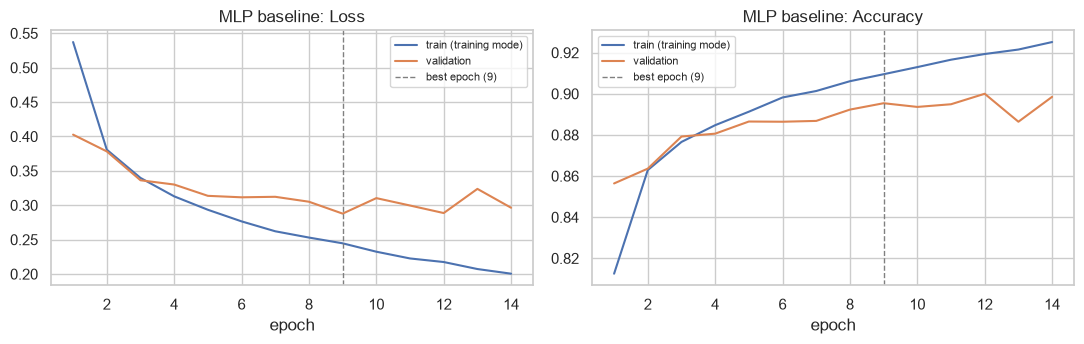

In [8]:
mlp = keras.Sequential([
    keras.Input(shape=INPUT_SHAPE),
    layers.Flatten(),
    layers.Dense(256, activation="relu"),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="mlp_baseline")
mlp.summary()
train(mlp, "MLP baseline")
plot_history("MLP baseline")

### Model 2: Basic convolutional neural network
Two convolution + max-pooling blocks learn local patterns (edges, collars, sleeves, soles) that are shared across positions in the image, followed by a small dense classifier. There is no explicit regularization beyond early stopping.

Model: "basic_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 28, 28)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 14, 14)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 14, 14)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 7, 7)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

...

Epoch 15/40


391/391 - 3s - 7ms/step - accuracy: 0.9714 - loss: 0.0794 - val_accuracy: 0.9277 - val_loss: 0.2435


Epoch 16/40


391/391 - 3s - 7ms/step - accuracy: 0.9759 - loss: 0.0692 - val_accuracy: 0.9224 - val_loss: 0.2566



Basic CNN: validation accuracy 0.9269 | train accuracy 0.9660 | best epoch 11 of 16 | 47s


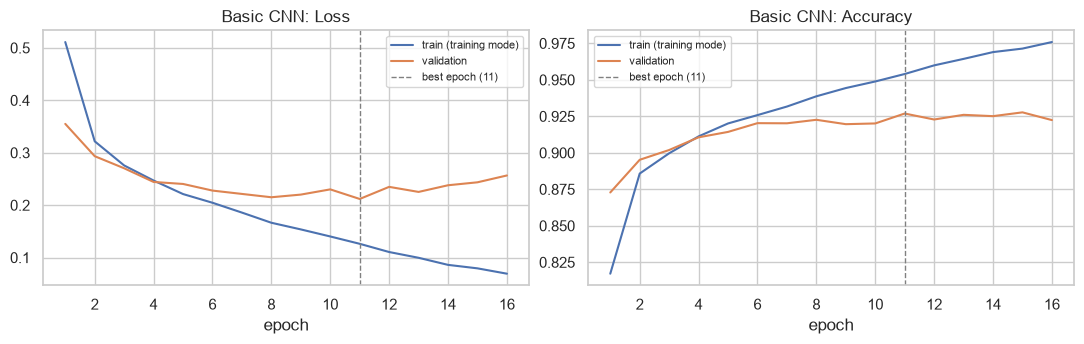

In [9]:
basic_cnn = keras.Sequential([
    keras.Input(shape=INPUT_SHAPE),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
], name="basic_cnn")
basic_cnn.summary()
train(basic_cnn, "Basic CNN")
plot_history("Basic CNN")

### Model 3: Regularized CNN
A deeper CNN designed to fight the overfitting seen in Model 2:
* **Data augmentation:** every training batch is randomly shifted by up to 2 pixels in each direction (the `ShiftedBatches` generator above). Validation and test images are never shifted.
* **Batch normalization** after each convolution, for faster and more stable training
* **Dropout** after each convolution block (25%) and before the output layer (50%)
* **Learning-rate schedule:** the learning rate is halved when validation loss plateaus for 2 epochs

Model: "regularized_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 32, 28, 28)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 28, 28)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 28, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 28, 28)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 28, 28)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 28, 28)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 14, 14)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 14, 14)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 64, 14, 14)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 14, 14)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 14, 14)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 14, 14)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 14, 14)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 14, 14)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 7, 7)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64, 7, 7)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       802,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 871,978 (3.33 MB)

 Trainable params: 871,082 (3.32 MB)

 Non-trainable params: 896 (3.50 KB)

...

Epoch 39/40


391/391 - 8s - 19ms/step - accuracy: 0.9418 - loss: 0.1600 - val_accuracy: 0.9493 - val_loss: 0.1441 - learning_rate: 1.5625e-05


Epoch 40/40


391/391 - 7s - 18ms/step - accuracy: 0.9414 - loss: 0.1603 - val_accuracy: 0.9490 - val_loss: 0.1444 - learning_rate: 1.5625e-05



Regularized CNN: validation accuracy 0.9493 | train accuracy 0.9654 | best epoch 39 of 40 | 286s


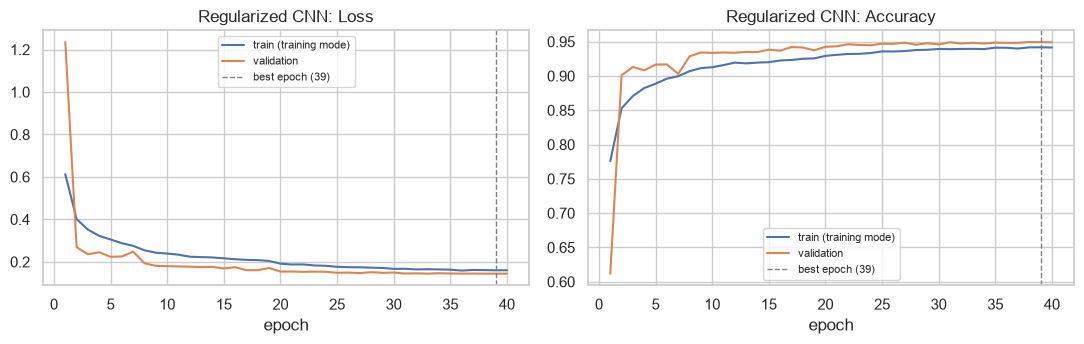

In [10]:
def conv_block(filters, dropout):
    return [
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(axis=1),  # normalize per channel (channels-first)
        layers.Activation("relu"),
        layers.Conv2D(filters, 3, padding="same", use_bias=False),
        layers.BatchNormalization(axis=1),
        layers.Activation("relu"),
        layers.MaxPooling2D(),
        layers.Dropout(dropout),
    ]


regularized_cnn = keras.Sequential([
    keras.Input(shape=INPUT_SHAPE),
    *conv_block(32, 0.25),
    *conv_block(64, 0.25),
    layers.Flatten(),
    layers.Dense(256, use_bias=False),
    layers.BatchNormalization(),
    layers.Activation("relu"),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
], name="regularized_cnn")
regularized_cnn.summary()

reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5)
train(regularized_cnn, "Regularized CNN", extra_callbacks=[reduce_lr], augment=True)
plot_history("Regularized CNN")

## 4. Model comparison and selection
Models are compared on the **validation set only**. The test set is reserved for the final, selected model.

In [11]:
comparison = pd.DataFrame(results).T.astype(float)
comparison = comparison.astype({"parameters": int, "epochs_run": int, "best_epoch": int})
display_table = comparison.copy()
for col in ["train_accuracy", "val_accuracy", "overfit_gap"]:
    display_table[col] = (100 * display_table[col]).round(2)
display_table["val_loss"] = display_table["val_loss"].round(4)
display_table.rename(columns={"train_accuracy": "train_acc_%", "val_accuracy": "val_acc_%", "overfit_gap": "gap_pts"})

,parameters,epochs_run,best_epoch,train_seconds,train_acc_%,val_acc_%,val_loss,gap_pts
MLP baseline,235146,14,9,26.1,91.65,89.54,0.2878,2.11
Basic CNN,421642,16,11,47.5,96.60,92.69,0.2118,3.91
Regularized CNN,871978,40,39,285.5,96.54,94.93,0.1441,1.61


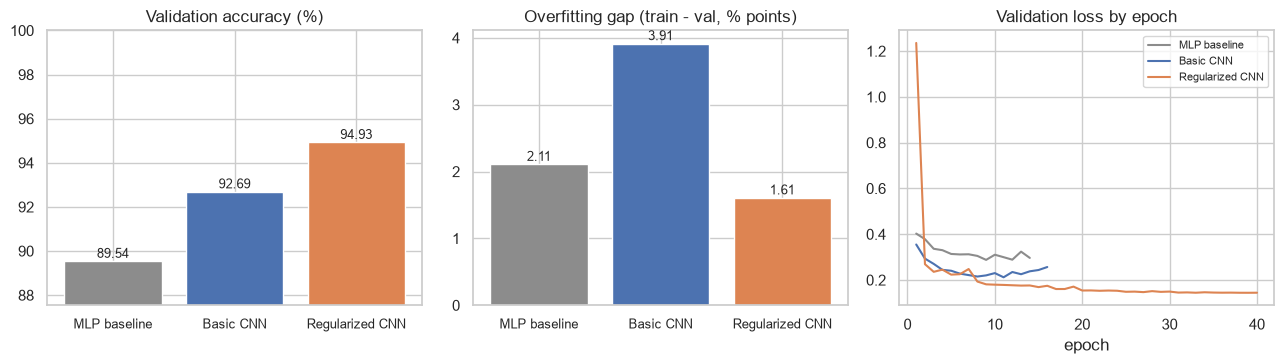

Selected model (highest validation accuracy): Regularized CNN


In [12]:
names = list(results)
colors = [MODEL_COLORS[n] for n in names]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))

val_pct = 100 * comparison["val_accuracy"]
axes[0].bar(names, val_pct, color=colors)
axes[0].set_ylim(val_pct.min() - 2, 100)
axes[0].set_title("Validation accuracy (%)")
for i, v in enumerate(val_pct):
    axes[0].text(i, v + 0.15, f"{v:.2f}", ha="center", fontsize=9)

gap_pts = 100 * comparison["overfit_gap"]
axes[1].bar(names, gap_pts, color=colors)
axes[1].set_title("Overfitting gap (train - val, % points)")
for i, v in enumerate(gap_pts):
    axes[1].text(i, v + 0.05, f"{v:.2f}", ha="center", fontsize=9)

for name in names:
    axes[2].plot(histories[name]["val_loss"], label=name, color=MODEL_COLORS[name])
axes[2].set_title("Validation loss by epoch")
axes[2].set_xlabel("epoch")
axes[2].legend(fontsize=8)

for ax in axes[:2]:
    ax.tick_params(axis="x", labelsize=9)
fig.tight_layout()
fig.savefig(FIG_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

best_name = comparison["val_accuracy"].astype(float).idxmax()
print(f"Selected model (highest validation accuracy): {best_name}")

## 5. Final evaluation on the held-out test set
The selected model is now evaluated once on the 10,000 test images it has never seen.

In [13]:
final_model = trained_models[best_name]
test_probs = final_model.predict(X_test, batch_size=512, verbose=0)
y_pred = test_probs.argmax(axis=1)
confidence = test_probs.max(axis=1)

test_accuracy = float((y_pred == y_test).mean())
test_macro_f1 = float(f1_score(y_test, y_pred, average="macro"))
print(f"{best_name}: test accuracy {test_accuracy:.4f} | macro F1 {test_macro_f1:.4f}")

# For transparency only (selection was already made on validation): test accuracy of every model
test_accuracy_all = {name: float(m.evaluate(X_test, y_test, batch_size=512, verbose=0)[1]) for name, m in trained_models.items()}
pd.Series(test_accuracy_all, name="test accuracy").round(4)

Regularized CNN: test accuracy 0.9410 | macro F1 0.9409


MLP baseline       0.8863
Basic CNN          0.9172
Regularized CNN    0.9410
Name: test accuracy, dtype: float64

In [14]:
report = classification_report(y_test, y_pred, target_names=CLASS_NAMES, output_dict=True)
per_class = pd.DataFrame(report).T.loc[CLASS_NAMES, ["precision", "recall", "f1-score"]]
per_class.sort_values("f1-score").round(3)

,precision,recall,f1-score
Shirt,0.818,0.807,0.813
T-shirt/top,0.901,0.885,0.893
Coat,0.890,0.935,0.912
Pullover,0.930,0.909,0.920
Dress,0.941,0.949,0.945
Sneaker,0.967,0.986,0.976
Ankle boot,0.984,0.969,0.976
Sandal,0.993,0.989,0.991
Trouser,0.994,0.989,0.991
Bag,0.992,0.992,0.992


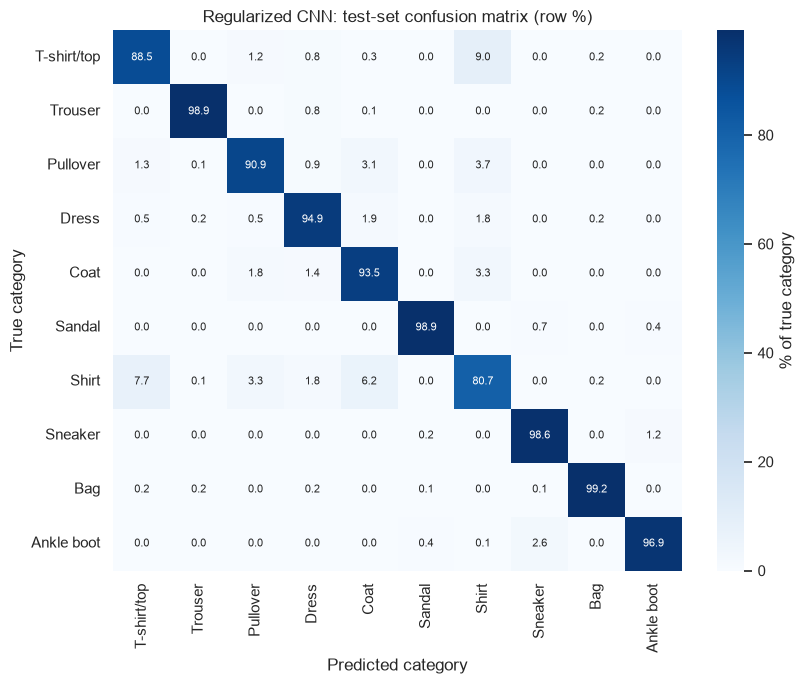

Total test errors: 590


,true,predicted,count
0,T-shirt/top,Shirt,90
1,Shirt,T-shirt/top,77
2,Shirt,Coat,62
3,Pullover,Shirt,37
4,Coat,Shirt,33
5,Shirt,Pullover,33
6,Pullover,Coat,31
7,Ankle boot,Sneaker,26


In [15]:
cm = confusion_matrix(y_test, y_pred)
cm_pct = 100 * cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(8.5, 7))
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
            cbar_kws={"label": "% of true category"}, ax=ax, annot_kws={"size": 8})
ax.set_xlabel("Predicted category")
ax.set_ylabel("True category")
ax.set_title(f"{best_name}: test-set confusion matrix (row %)")
fig.tight_layout()
fig.savefig(FIG_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

off_diagonal = [(CLASS_NAMES[i], CLASS_NAMES[j], int(cm[i, j])) for i in range(10) for j in range(10) if i != j]
confused_pairs = pd.DataFrame(off_diagonal, columns=["true", "predicted", "count"])
confused_pairs = confused_pairs.sort_values("count", ascending=False).head(8).reset_index(drop=True)
print(f"Total test errors: {int((y_pred != y_test).sum())}")
confused_pairs

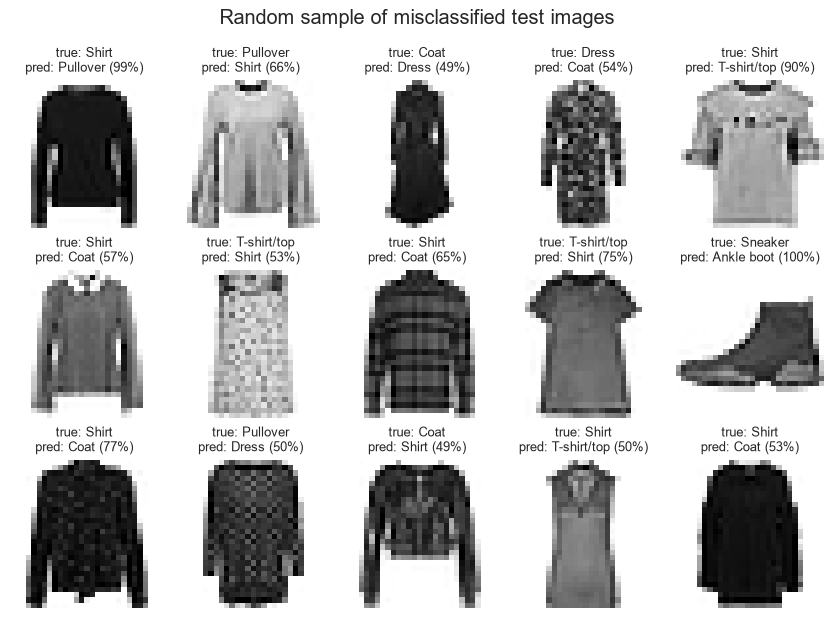

In [16]:
wrong = np.flatnonzero(y_pred != y_test)
picks = rng.choice(wrong, 15, replace=False)
fig, axes = plt.subplots(3, 5, figsize=(8.5, 6.4))
for ax, i in zip(axes.flat, picks):
    ax.imshow(x_test[i], cmap="gray_r")
    ax.set_title(f"true: {CLASS_NAMES[y_test[i]]}\npred: {CLASS_NAMES[y_pred[i]]} ({confidence[i]:.0%})", fontsize=9.5)
    ax.axis("off")
fig.suptitle("Random sample of misclassified test images")
fig.tight_layout()
fig.savefig(FIG_DIR / "misclassified.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Business view: confidence thresholds for human-in-the-loop tagging
In production, the model doesn't have to tag *every* image. If its confidence (the highest softmax probability) is below a threshold, the image goes to a human. The trade-off is **coverage** (the share of images tagged automatically) against **accuracy on those auto-tagged images**.

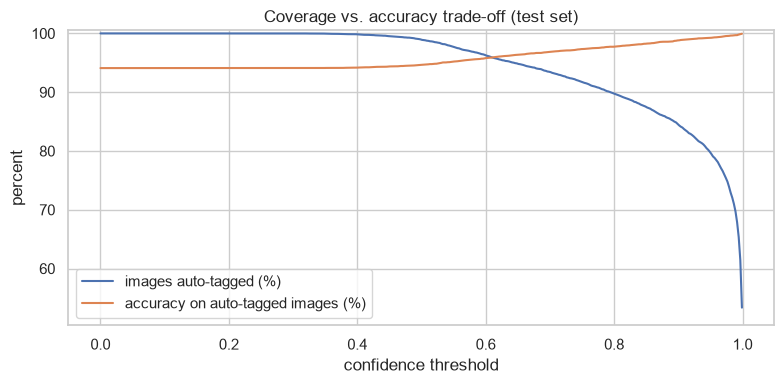

,threshold,auto_tagged_pct,accuracy_on_auto_tagged_pct,sent_to_human
0,0.00,100.00,94.10,0
1,0.50,98.93,94.65,107
2,0.60,96.28,95.80,372
3,0.70,93.43,96.86,657
4,0.80,89.76,97.74,1024
5,0.90,84.49,98.80,1551
6,0.95,79.68,99.25,2032
7,0.97,76.33,99.49,2367
8,0.98,73.47,99.59,2653
9,0.99,69.10,99.70,3090


In [17]:
thresholds = [0.0, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.97, 0.98, 0.99]
rows = []
for t in thresholds:
    mask = confidence >= t
    rows.append({"threshold": t, "auto_tagged_pct": 100 * mask.mean(),
                 "accuracy_on_auto_tagged_pct": 100 * (y_pred[mask] == y_test[mask]).mean(),
                 "sent_to_human": int((~mask).sum())})
threshold_table = pd.DataFrame(rows).round(2)

grid = np.linspace(0, 0.999, 400)
coverage_curve = [100 * (confidence >= t).mean() for t in grid]
accuracy_curve = [100 * (y_pred[confidence >= t] == y_test[confidence >= t]).mean() for t in grid]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(grid, coverage_curve, label="images auto-tagged (%)", color="#4c72b0")
ax.plot(grid, accuracy_curve, label="accuracy on auto-tagged images (%)", color="#dd8452")
ax.set_xlabel("confidence threshold")
ax.set_ylabel("percent")
ax.set_ylim(min(coverage_curve) - 3, 100.5)
ax.set_title("Coverage vs. accuracy trade-off (test set)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "confidence_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()
threshold_table

In [18]:
# Persist the final model and every number the stakeholder report relies on
final_model.save(OUT_DIR / "final_model.keras")

summary = {
    "selected_model": best_name,
    "comparison": comparison.astype(float).to_dict(orient="index"),
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_accuracy_all_models": test_accuracy_all,
    "per_class": per_class.to_dict(orient="index"),
    "confused_pairs": confused_pairs.to_dict(orient="records"),
    "threshold_table": threshold_table.to_dict(orient="records"),
    "most_similar_mean_images": most_similar.to_dict(orient="records"),
    "test_errors": int((y_pred != y_test).sum()),
    "environment": {"keras": keras.__version__, "backend": keras.backend.backend()},
}
(OUT_DIR / "metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT_DIR / "final_model.keras", "and", OUT_DIR / "metrics.json")

Saved: results\final_model.keras and results\metrics.json


In [19]:
operating = threshold_table[(threshold_table["threshold"] > 0) & (threshold_table["accuracy_on_auto_tagged_pct"] >= 99)].iloc[0]
print(f"Recommended model: {best_name}")
print(f"  test accuracy {test_accuracy:.2%}, macro F1 {test_macro_f1:.3f} "
      f"(MLP baseline: {test_accuracy_all['MLP baseline']:.2%}, basic CNN: {test_accuracy_all['Basic CNN']:.2%})")
print(f"  overfitting gap: basic CNN {comparison.loc['Basic CNN', 'overfit_gap']:.2%} -> "
      f"{best_name} {comparison.loc[best_name, 'overfit_gap']:.2%}")
print(f"  hardest category: {per_class['f1-score'].idxmin()} (F1 {per_class['f1-score'].min():.3f})")
print(f"  at confidence >= {operating['threshold']}: {operating['auto_tagged_pct']:.1f}% auto-tagged "
      f"at {operating['accuracy_on_auto_tagged_pct']:.2f}% accuracy")

Recommended model: Regularized CNN
  test accuracy 94.10%, macro F1 0.941 (MLP baseline: 88.63%, basic CNN: 91.72%)
  overfitting gap: basic CNN 3.91% -> Regularized CNN 1.61%
  hardest category: Shirt (F1 0.813)
  at confidence >= 0.95: 79.7% auto-tagged at 99.25% accuracy


## 7. Key findings and next steps

**Findings**
* **Convolution is the biggest lever.** Going from the MLP to a CNN gave the largest accuracy jump, because convolutions use the 2-D structure of the image.
* **Regularization makes the CNN generalize.** The basic CNN started memorizing the training set. Augmentation, dropout and batch normalization shrank the overfitting gap and produced the best validation and test accuracy.
* **Errors are concentrated and predictable.** Most mistakes are among the upper-body garments (T-shirt/top, Shirt, Pullover, Coat), exactly the categories whose average images were nearly identical in the exploration. Shirt is the hardest class.
* **Confidence thresholds create a practical workflow.** Auto-tagging only confident predictions keeps automated accuracy above 99% while still covering most images. The rest go to human review.

**Limitations and next steps**
* Fashion-MNIST is small, grayscale and centered. The approach should be re-validated on the retailer's real color photos, ideally by fine-tuning a pretrained network (transfer learning).
* Collect more examples, or attribute labels such as collar type and sleeve length, for the confusable upper-body categories.
* Tune hyperparameters systematically, average over several random seeds, and allow a longer epoch budget (the regularized CNN was still improving slowly at the epoch limit).
* Calibrate confidence scores (for example with temperature scaling) before relying on thresholds in production, and monitor the automation rate and reviewer corrections over time.